# Elasticity, LTV and break-even discounts

How price-sensitive are customers, when does a discount pay for itself, and how deep should an intro offer be? This notebook simulates two years of weekly web-store sales in six markets, estimates price elasticity properly, and turns it into discount and intro-offer decisions.

**Key formulas**

| What | Formula |
|---|---|
| Price elasticity | $E = \%\Delta Q \,/\, \%\Delta P$; arc version divides each change by the average of the two values |
| Log-log demand model | $\ln Q = a + E \ln P + \text{controls}$ — the coefficient on $\ln P$ is the elasticity |
| Volume needed for a discount to break even | $\dfrac{d}{m-d}$ ($d$ = discount, $m$ = contribution margin, both as shares of price) |
| Volume a discount actually brings (constant $E$) | $(1-d)^{E} - 1$ |
| Profit-maximising price (Lerner rule) | $\dfrac{P-C}{P} = \dfrac{1}{\lvert E\rvert}$ |
| Customer lifetime value | $LTV = m\left(p_{1} + p\,\dfrac{r}{1-r}\right)$ — first-year price $p_1$, renewal price $p$, renewal rate $r$ |

Sections:
1. The slide examples
2. Simulate weekly sales
3. Why naive elasticity is wrong: promotions come with marketing
4. Estimating elasticity properly
5. When does a discount pay for itself?
6. Profit by discount depth and the best discount per market
7. Break-even table for any margin
8. Intro offers: new customers vs first-year profit vs LTV
9. Takeaways

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.width", 120)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "font.size": 10.5,
})

C = {"base": "#3F3A52", "accent": "#5B21B6", "pink": "#B8166F", "good": "#17784F",
     "warn": "#D97706", "teal": "#0E7490", "grey": "#8A8F98"}
MKT_COLORS = ["#5B21B6", "#8B7BC4", "#0E7490", "#17784F", "#D97706", "#B8166F"]
pct = mticker.PercentFormatter(1, decimals=0)

## 1. The slide examples

In [2]:
def arc_elasticity(p0, p1, q0, q1):
    return ((q1 - q0) / ((q1 + q0) / 2)) / ((p1 - p0) / ((p1 + p0) / 2))

def ltv(first_price, renewal_price, renewal_rate, margin):
    return margin * (first_price + renewal_price * renewal_rate / (1 - renewal_rate))

def breakeven_uplift(d, m):
    return d / (m - d)

e = arc_elasticity(49.99, 54.99, 10_000, 9_300)
print(f"Arc elasticity, €49.99→€54.99 and 10,000→9,300 units: {e:.2f}")
print(f"Revenue change: {54.99 * 9_300 / (49.99 * 10_000) - 1:+.1%}")
print(f"LTV with €45 a year, 85% margin, 60% renewal: €{ltv(45, 45, 0.60, 0.85):.1f}")
print(f"Volume needed for a 20% discount at 70% margin: {breakeven_uplift(0.20, 0.70):+.0%}")

Arc elasticity, €49.99→€54.99 and 10,000→9,300 units: -0.76
Revenue change: +2.3%
LTV with €45 a year, 85% margin, 60% renewal: €95.6
Volume needed for a 20% discount at 70% margin: +40%


## 2. Simulate weekly sales

Six markets, 104 weeks, one subscription product sold in the web store. Built-in assumptions, so we know what the analysis should find:

- **True elasticities** differ by market: inelastic in DE, FR and UK (about −0.9 to −1.2), elastic in BR, TR and IN (−1.8 to −2.4).
- About a quarter of weeks have a promotion (10–40% off). **Deeper promotions usually come with a marketing push** (emails, banners) that lifts demand on its own — the classic trap for elasticity estimates.
- Black Friday weeks have the deepest discounts and a seasonal demand spike.
- Contribution margin is **65%** of the net price: what's left after payment fees, affiliate commissions, support and infrastructure.

In [3]:
rng = np.random.default_rng(7)

markets = pd.DataFrame({
    "market": ["DE", "UK", "FR", "BR", "TR", "IN"],
    "true_elasticity": [-0.9, -1.2, -1.1, -1.8, -2.1, -2.4],
    "list_price": [59.99, 54.99, 59.99, 29.99, 24.99, 19.99],   # EUR equivalent, ex-VAT
    "base_units": [900, 700, 600, 800, 500, 1200],
})
MARGIN = 0.65
weeks = pd.date_range("2025-01-06", periods=104, freq="W-MON")

rows = []
for _, mk in markets.iterrows():
    woy = weeks.isocalendar().week.to_numpy()
    promo = rng.random(len(weeks)) < 0.25
    disc = np.where(promo, rng.choice([0.10, 0.20, 0.30, 0.40], len(weeks), p=[.35, .35, .2, .1]), 0.0)
    black_friday = np.isin(woy, [47, 48])
    disc = np.where(black_friday, 0.40, disc)
    marketing = np.where(disc >= 0.20, rng.random(len(weeks)) < 0.75, rng.random(len(weeks)) < 0.05)
    season = 1 + 0.10 * np.sin(2 * np.pi * (woy - 10) / 52) + 0.45 * black_friday
    price = mk["list_price"] * (1 - disc)
    lam = (mk["base_units"] * season * (1 + 0.35 * marketing)
           * (price / mk["list_price"]) ** mk["true_elasticity"] * rng.lognormal(0, 0.06, len(weeks)))
    rows.append(pd.DataFrame({
        "week": weeks, "market": mk["market"], "list_price": mk["list_price"],
        "discount": disc, "price": price.round(2), "marketing": marketing.astype(int),
        "black_friday": black_friday.astype(int), "week_of_year": woy,
        "units": rng.poisson(lam),
    }))
sales = pd.concat(rows, ignore_index=True)
sales["revenue"] = sales["units"] * sales["price"]
print(f"{len(sales):,} market-weeks")
sales.head()

624 market-weeks


,week,market,list_price,discount,price,marketing,black_friday,week_of_year,units,revenue
0,2025-01-06,DE,59.990,0.000,59.990,0,0,2,725,"43,492.750"
1,2025-01-13,DE,59.990,0.000,59.990,0,0,3,862,"51,711.380"
2,2025-01-20,DE,59.990,0.000,59.990,0,0,4,824,"49,431.760"
3,2025-01-27,DE,59.990,0.200,47.990,1,0,5,1459,"70,017.410"
4,2025-02-03,DE,59.990,0.000,59.990,0,0,6,825,"49,491.750"


## 3. Why naive elasticity is wrong: promotions come with marketing

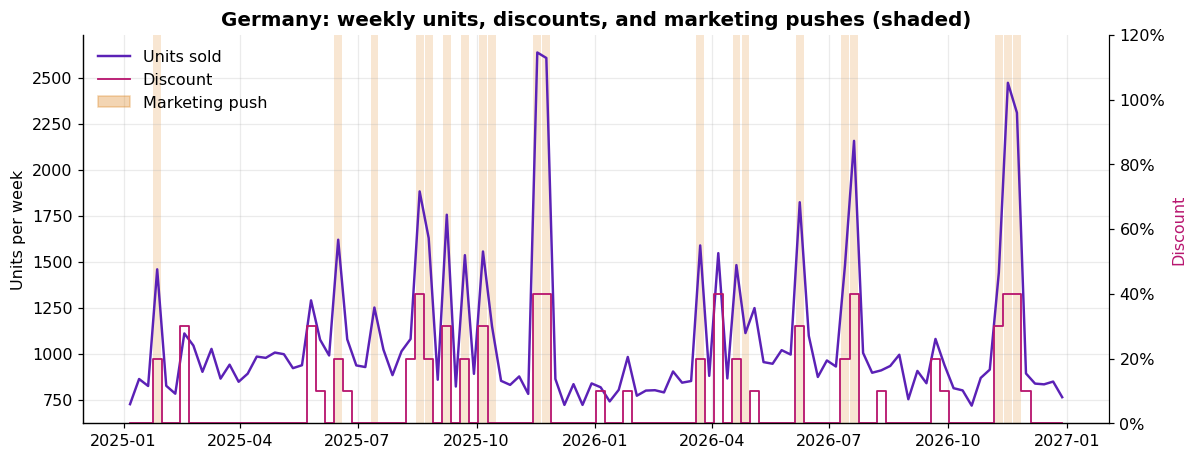

Share of weeks with a marketing push, by discount depth:


,marketing share
discount,
0.000,0.054
0.100,0.033
0.200,0.712
0.300,0.759
0.400,0.825


In [4]:
de = sales[sales["market"] == "DE"]
fig, ax = plt.subplots(figsize=(11, 4.3))
ax.plot(de["week"], de["units"], color=C["accent"], lw=1.6, label="Units sold")
for w in de.loc[de["marketing"] == 1, "week"]:
    ax.axvspan(w - pd.Timedelta(days=3), w + pd.Timedelta(days=3), color=C["warn"], alpha=0.18, lw=0)
ax2 = ax.twinx()
ax2.step(de["week"], de["discount"], where="mid", color=C["pink"], lw=1.2, label="Discount")
ax2.yaxis.set_major_formatter(pct); ax2.set_ylim(0, 1.2); ax2.grid(False)
ax2.spines["right"].set_visible(True)
ax.set_ylabel("Units per week"); ax2.set_ylabel("Discount", color=C["pink"])
ax.set_title("Germany: weekly units, discounts, and marketing pushes (shaded)")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2 + [plt.Rectangle((0, 0), 1, 1, color=C["warn"], alpha=0.3)],
          l1 + l2 + ["Marketing push"], frameon=False, loc="upper left")
fig.tight_layout(); plt.show()

print("Share of weeks with a marketing push, by discount depth:")
sales.groupby("discount")["marketing"].mean().to_frame("marketing share")

Spikes in sales line up with discounts — but also with marketing pushes, which almost always accompany deep promotions. If we regress sales on price alone, the model credits the marketing lift to the price cut and **overstates price sensitivity**. Black Friday adds the same problem with seasonality.

## 4. Estimating elasticity properly

We compare two log-log regressions per market (plain numpy least squares):

- **Naive:** $\ln Q = a + E \ln P$
- **Controlled:** $\ln Q = a + E \ln P + \beta \cdot \text{marketing} + \gamma \cdot \text{Black Friday} + \text{seasonality terms}$

In [5]:
def ols(X, y):
    X = np.column_stack([np.ones(len(y)), X])
    coef, *_ = np.linalg.lstsq(X, y, rcond=None)
    resid = y - X @ coef
    sigma2 = resid @ resid / (len(y) - X.shape[1])
    se = np.sqrt(np.diag(sigma2 * np.linalg.inv(X.T @ X)))
    return coef, se

def elasticity(d, controlled=True):
    y = np.log(d["units"].clip(lower=1))
    x = [np.log(d["price"])]
    if controlled:
        w = 2 * np.pi * d["week_of_year"] / 52
        x += [d["marketing"], d["black_friday"], np.sin(w), np.cos(w)]
    coef, se = ols(np.column_stack(x), y)
    return coef[1], se[1]

est = []
for mkt, d in sales.groupby("market", sort=False):
    n_e, n_se = elasticity(d, controlled=False)
    c_e, c_se = elasticity(d, controlled=True)
    est.append({"market": mkt, "naive": n_e, "controlled": c_e, "controlled_se": c_se})
est = pd.DataFrame(est).merge(markets[["market", "true_elasticity"]], on="market").set_index("market")
est["naive bias"] = est["naive"] - est["true_elasticity"]
est

,naive,controlled,controlled_se,true_elasticity,naive bias
market,,,,,
DE,-1.725,-0.949,0.070,-0.900,-0.825
UK,-1.893,-1.227,0.072,-1.200,-0.693
FR,-2.024,-1.140,0.088,-1.100,-0.924
BR,-2.594,-1.794,0.072,-1.800,-0.794
TR,-2.760,-2.206,0.086,-2.100,-0.660
IN,-3.202,-2.471,0.071,-2.400,-0.802


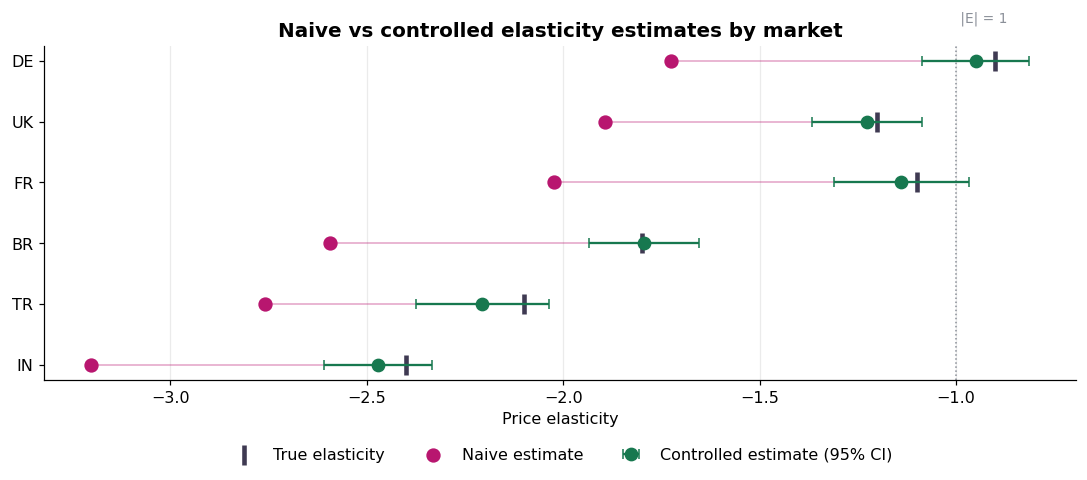

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.6))
y = np.arange(len(est))[::-1]
ax.scatter(est["true_elasticity"], y, s=160, marker="|", color=C["base"], lw=3, label="True elasticity", zorder=3)
ax.scatter(est["naive"], y, s=70, color=C["pink"], label="Naive estimate", zorder=4)
ax.errorbar(est["controlled"], y, xerr=1.96 * est["controlled_se"], fmt="o", ms=8,
            color=C["good"], ecolor=C["good"], capsize=3, label="Controlled estimate (95% CI)", zorder=5)
for yi, (n, t) in zip(y, zip(est["naive"], est["true_elasticity"])):
    ax.plot([n, t], [yi, yi], color=C["pink"], lw=1, alpha=0.4)
ax.set_yticks(y, est.index)
ax.axvline(-1, color=C["grey"], ls=":", lw=1)
ax.text(-1, len(est) - 0.35, " |E| = 1", color=C["grey"], fontsize=9)
ax.set_xlabel("Price elasticity")
ax.set_title("Naive vs controlled elasticity estimates by market")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3)
ax.grid(axis="y", visible=False)
fig.tight_layout(); plt.show()

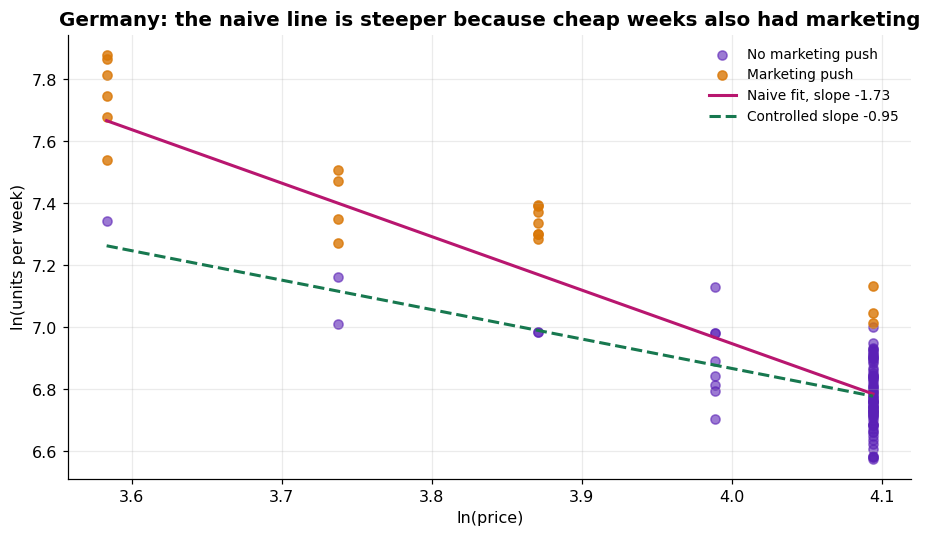

In [7]:
d = sales[sales["market"] == "DE"]
lp, lq = np.log(d["price"]), np.log(d["units"])
coef_naive, _ = ols(lp.to_numpy()[:, None], lq.to_numpy())
xs = np.linspace(lp.min(), lp.max(), 50)

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.scatter(lp[d["marketing"] == 0], lq[d["marketing"] == 0], color=C["accent"], alpha=0.6, label="No marketing push")
ax.scatter(lp[d["marketing"] == 1], lq[d["marketing"] == 1], color=C["warn"], alpha=0.8, label="Marketing push")
ax.plot(xs, coef_naive[0] + coef_naive[1] * xs, color=C["pink"], lw=2, label=f"Naive fit, slope {coef_naive[1]:.2f}")
mean_x, mean_y = lp[d["marketing"] == 0].mean(), lq[d["marketing"] == 0].mean()
ce = est.loc["DE", "controlled"]
ax.plot(xs, mean_y + ce * (xs - mean_x), color=C["good"], lw=2, ls="--", label=f"Controlled slope {ce:.2f}")
ax.set_xlabel("ln(price)"); ax.set_ylabel("ln(units per week)")
ax.set_title("Germany: the naive line is steeper because cheap weeks also had marketing")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout(); plt.show()

The naive estimate makes demand look more elastic than it is in every market. In an interview, name the general problem: **prices aren't set randomly** — promotions coincide with marketing, seasons and competitor moves. Fixes, from best to simplest: randomised price tests, control markets (difference-in-differences), or at least controlling for the known drivers as here.

From now on we use the **true** elasticities to keep the decision logic clear; in practice you'd use the controlled estimates with their confidence intervals.

## 5. When does a discount pay for itself?

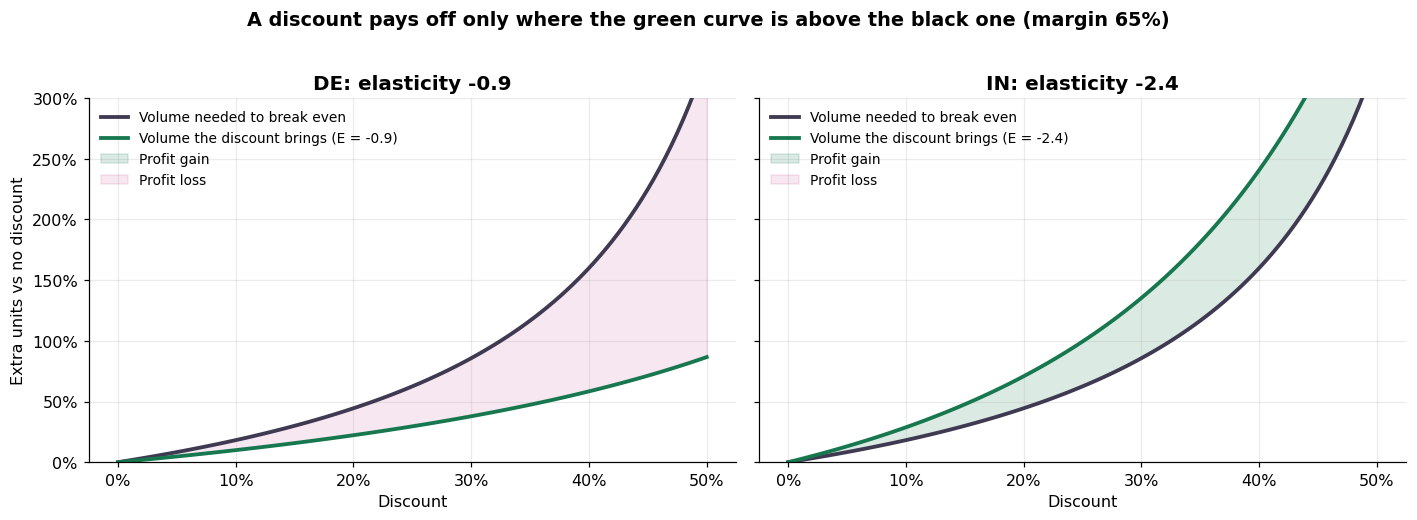

At 65% margin a 20% discount needs +44% more units.
  DE (E = -0.9): a 20% discount brings +22%
  BR (E = -1.8): a 20% discount brings +49%
  IN (E = -2.4): a 20% discount brings +71%


In [8]:
ds = np.linspace(0, 0.5, 101)
need = breakeven_uplift(ds, MARGIN)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, mkt in zip(axes, ["DE", "IN"]):
    E = markets.set_index("market").loc[mkt, "true_elasticity"]
    gets = (1 - ds) ** E - 1
    ax.plot(ds, need, color=C["base"], lw=2.5, label="Volume needed to break even")
    ax.plot(ds, gets, color=C["good"], lw=2.5,
            label=f"Volume the discount brings (E = {E})")
    ax.fill_between(ds, need, gets, where=gets > need, color=C["good"], alpha=0.15, label="Profit gain")
    ax.fill_between(ds, need, gets, where=gets <= need, color=C["pink"], alpha=0.10, label="Profit loss")
    ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct)
    ax.set_ylim(0, 3); ax.set_xlabel("Discount")
    ax.set_title(f"{mkt}: elasticity {E}")
    ax.legend(frameon=False, fontsize=9, loc="upper left")
axes[0].set_ylabel("Extra units vs no discount")
fig.suptitle(f"A discount pays off only where the green curve is above the black one (margin {MARGIN:.0%})",
             fontweight="bold", y=1.02)
fig.tight_layout(); plt.show()

print(f"At {MARGIN:.0%} margin a 20% discount needs {breakeven_uplift(0.2, MARGIN):+.0%} more units.")
for mkt in ["DE", "BR", "IN"]:
    E = markets.set_index("market").loc[mkt, "true_elasticity"]
    print(f"  {mkt} (E = {E}): a 20% discount brings {(0.8) ** E - 1:+.0%}")

In an inelastic market like Germany the discount never brings enough extra volume — every promotion loses profit. In an elastic market like India, moderate discounts pay off. **The same promo calendar applied globally is almost always wrong.**

## 6. Profit by discount depth and the best discount per market

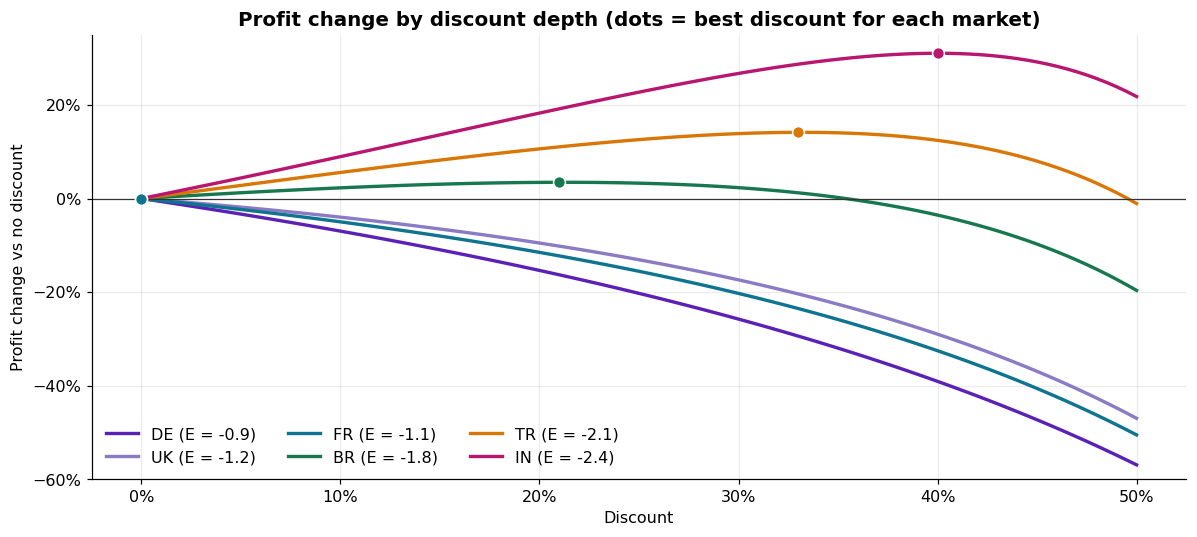

,elasticity,best discount (grid),best discount (Lerner),profit change at best,profit change at 20% off
market,,,,,
DE,-0.900,0.000,0.000,0.000,-0.154
UK,-1.200,0.000,0.000,0.000,-0.095
FR,-1.100,0.000,0.000,0.000,-0.115
BR,-1.800,0.210,0.213,0.035,0.035
TR,-2.100,0.330,0.332,0.142,0.106
IN,-2.400,0.400,0.400,0.311,0.183


In [9]:
def profit_change(d, E, m=MARGIN):
    return (m - d) / m * (1 - d) ** E - 1      # vs no discount, constant elasticity

fig, ax = plt.subplots(figsize=(11, 5))
best = []
for (mkt, E), col in zip(markets[["market", "true_elasticity"]].itertuples(index=False), MKT_COLORS):
    pc = profit_change(ds, E)
    ax.plot(ds, pc, color=col, lw=2.2, label=f"{mkt} (E = {E})")
    i = pc.argmax()
    ax.scatter(ds[i], pc[i], color=col, s=60, zorder=5, edgecolor="white")
    lerner = 1 - (1 - MARGIN) / (1 - 1 / abs(E)) if abs(E) > 1 else np.nan
    best.append({"market": mkt, "elasticity": E, "best discount (grid)": ds[i],
                 "best discount (Lerner)": max(lerner, 0) if not np.isnan(lerner) else 0.0,
                 "profit change at best": pc[i],
                 "profit change at 20% off": profit_change(0.2, E)})
ax.axhline(0, color="#333", lw=0.8)
ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct)
ax.set_xlabel("Discount"); ax.set_ylabel("Profit change vs no discount")
ax.set_ylim(-0.6, 0.35)
ax.set_title("Profit change by discount depth (dots = best discount for each market)")
ax.legend(frameon=False, ncol=3, loc="lower left")
fig.tight_layout(); plt.show()

pd.DataFrame(best).set_index("market")

The grid search and the Lerner rule agree: inelastic markets should not be discounted at all (if anything, prices there could rise), elastic markets have a moderate profit-maximising discount.

**Caveat:** a constant-elasticity model ignores reference-price effects — frequent deep discounts teach customers to wait for the next promotion and lower the price they consider "normal". Treat these numbers as an upper bound on how deep to go.

## 7. Break-even table for any margin

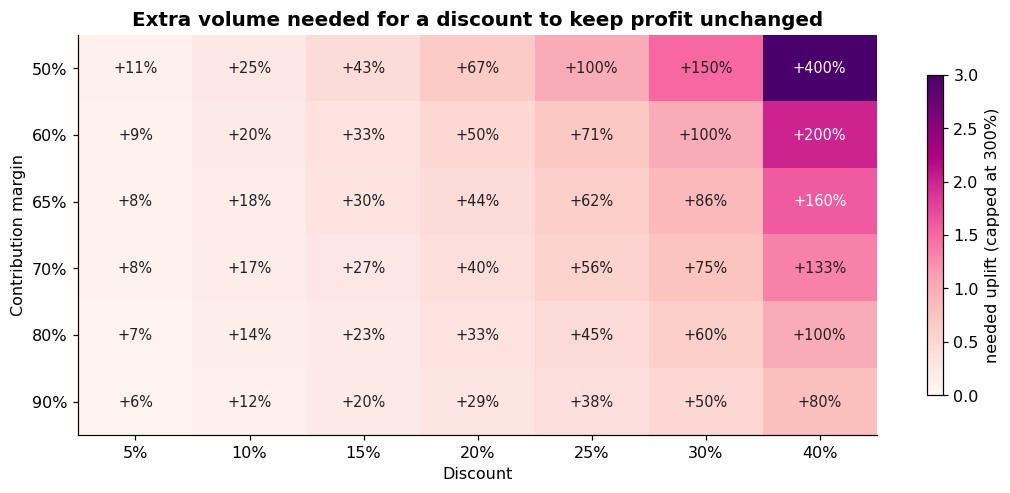

In [10]:
margins = np.array([0.50, 0.60, 0.65, 0.70, 0.80, 0.90])
discounts = np.array([0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40])
tab = pd.DataFrame([[breakeven_uplift(d, m) for d in discounts] for m in margins],
                   index=[f"{m:.0%}" for m in margins], columns=[f"{d:.0%}" for d in discounts])

fig, ax = plt.subplots(figsize=(10, 4.6))
im = ax.imshow(np.minimum(tab.values, 3), cmap="RdPu", aspect="auto", vmin=0, vmax=3)
for i in range(tab.shape[0]):
    for j in range(tab.shape[1]):
        v = tab.values[i, j]
        ax.text(j, i, f"+{v:.0%}", ha="center", va="center", fontsize=9.5,
                color="white" if v > 1.5 else "#222")
ax.set_xticks(range(len(discounts)), tab.columns); ax.set_yticks(range(len(margins)), tab.index)
ax.set_xlabel("Discount"); ax.set_ylabel("Contribution margin")
ax.set_title("Extra volume needed for a discount to keep profit unchanged")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="needed uplift (capped at 300%)")
fig.tight_layout(); plt.show()

A handy table for any promo discussion: at a 65% margin, 10% off needs about +18% volume, 20% off needs +44%, and 30% off needs +86%. The lower the margin, the faster the requirement explodes — relevant for channels with high partner or app-store fees.

## 8. Intro offers: new customers vs first-year profit vs LTV

A first-year discount attracts more new customers, but with diminishing returns, and **deal-seekers renew less often** at full price. We compare three ways to judge the intro discount, per 1,000 store visitors:

- **New customers** — what an acquisition team might optimise;
- **First-year profit** — what a short-term revenue target rewards;
- **LTV** — first-year profit plus all future renewals.

Assumptions: list price €60 a year, 65% margin, 3% conversion at full price; conversion lift saturates at about +150%; renewal rate falls from 62% by 0.5 pp for each 1 pp of intro discount.

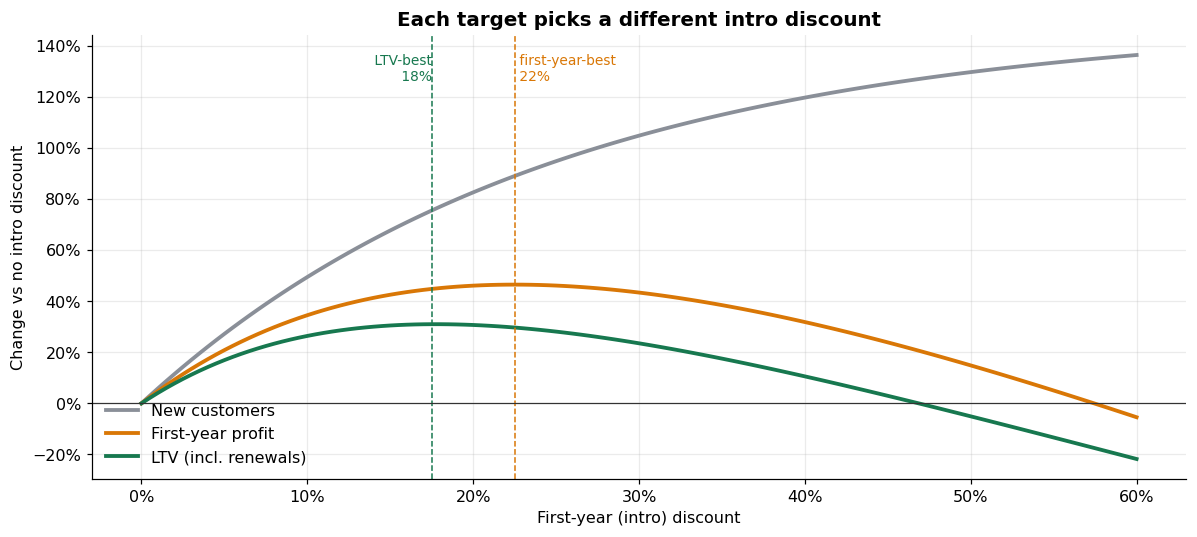

,new customers,renewal rate,first-year profit,LTV
intro discount,,,,
0%,30.000,62%,"€1,170","€3,079"
0%,30.900,62%,"€1,199","€3,144"
10%,44.200,57%,"€1,561","€3,871"
10%,44.800,57%,"€1,574","€3,892"
10%,45.400,57%,"€1,586","€3,911"
20%,54.400,52%,"€1,707","€4,027"
20%,54.800,52%,"€1,709","€4,024"
20%,55.200,52%,"€1,711","€4,019"
30%,61.200,47%,"€1,682","€3,819"


In [11]:
P, C0 = 60.0, 0.03
dd = np.linspace(0, 0.6, 121)
conv = C0 * (1 + 1.5 * (1 - np.exp(-dd / 0.25)))
renew = 0.62 - 0.5 * dd
customers = 1000 * conv
first_year = customers * MARGIN * P * (1 - dd)
lifetime = customers * ltv(P * (1 - dd), P, renew, MARGIN)

intro = pd.DataFrame({"intro discount": dd, "new customers": customers, "renewal rate": renew,
                      "first-year profit": first_year, "LTV": lifetime})
best_fy = intro.loc[intro["first-year profit"].idxmax(), "intro discount"]
best_ltv = intro.loc[intro["LTV"].idxmax(), "intro discount"]

fig, ax = plt.subplots(figsize=(11, 5))
for col, color, label in [("new customers", C["grey"], "New customers"),
                          ("first-year profit", C["warn"], "First-year profit"),
                          ("LTV", C["good"], "LTV (incl. renewals)")]:
    ax.plot(dd, intro[col] / intro[col].iloc[0] - 1, color=color, lw=2.5, label=label)
ax.axvline(best_fy, color=C["warn"], ls="--", lw=1)
ax.axvline(best_ltv, color=C["good"], ls="--", lw=1)
ax.text(best_ltv, ax.get_ylim()[1] * 0.95, f" LTV-best\n {best_ltv:.0%}", color=C["good"], fontsize=9, va="top", ha="right")
ax.text(best_fy, ax.get_ylim()[1] * 0.95, f" first-year-best\n {best_fy:.0%}", color=C["warn"], fontsize=9, va="top")
ax.axhline(0, color="#333", lw=0.8)
ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct)
ax.set_xlabel("First-year (intro) discount"); ax.set_ylabel("Change vs no intro discount")
ax.set_title("Each target picks a different intro discount")
ax.legend(frameon=False, loc="lower left")
fig.tight_layout(); plt.show()

show = intro[intro["intro discount"].round(2).isin([0, 0.1, 0.2, 0.3, 0.4, 0.5])].set_index("intro discount")
show = show.assign(**{"renewal rate": show["renewal rate"].map("{:.0%}".format),
                      "first-year profit": show["first-year profit"].map("€{:,.0f}".format),
                      "LTV": show["LTV"].map("€{:,.0f}".format),
                      "new customers": show["new customers"].round(1)})
show.index = show.index.map("{:.0%}".format)
show

Optimising **new customers** pushes the discount ever deeper. **First-year profit** peaks a bit lower, and **LTV** peaks lower still, because deeply discounted customers renew less often. Agreeing on the objective — and measuring renewal rates of discount-acquired cohorts — matters more than fine-tuning the discount itself.

## 9. Takeaways

- **Estimate elasticity with controls or experiments.** Promotions coincide with marketing and seasons, so a naive price-only regression overstates price sensitivity.
- **Elasticity differs by market.** Inelastic markets lose money on promotions; elastic markets can gain. Localise promo depth instead of running one global calendar.
- **Check the break-even before any discount:** needed volume $= d/(m-d)$; at 65% margin, 20% off needs +44% units.
- **Use the Lerner rule as a sanity check** for the profit-maximising price, and remember that constant-elasticity models overstate how deep to discount.
- **Judge intro offers on LTV, not on new customers or first-year revenue** — deal-seekers renew less.

**Try it yourself:** change `true_elasticity`, `MARGIN`, the marketing lift (`0.35 * marketing`) or the renewal penalty (`0.5 * dd`) and rerun.